<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
    <h1>Sujet 5: Réponses du système climatique <br>à des émissions impulsionnelles des carbones</h1>
    <br>
    <strong>Main topics covered here:</strong>
</center>

## Introduction

The increase of greenhouse gas concentration in the atmosphere, mostly due to human activities (fossil fuel combustion, cement production, agriculture, deforestation), exerts a radiative forcing to the climate system. This results in climate change, which acts to counteract the forcing. Due to its high warming potential, CO$_2$ has historically been associated with global warming and climate change. Indeed, direct measurements of atmospheric CO$_2$ started in 1959 (with Keeling in Revelle at Mona Loa), while earlier measurements are derived from paleo-climatic data like ice-core and other indirect evidences.

Understanding how the atmospheric CO$_2$ evolves is thus essential to characterize the response timescales of Earth System models. For instance, the responses of CO$_2$ and other climate variables to an emission pulse into the atmosphere are often used to compute the Global Warming Potential (GWP) and Global Temperature change Potential (GTP). 

When discussing the effect of anthropogenic emissions on atmospheric carbon dioxide, time scales of tens to several hundred years are relevant. Over these timescales, the concentration of CO$_2$ in the atmosphere is influenced by a range of processes involving human activities (such as the combustion of fossil fuels, cement production, agriculture and deforestation), the land biosphere and the oceans ([Fig. 1](#tp5-fig1)).

The temporal evolution of atmospheric CO$_2$ can be written as follows :

$$ \frac{d \text{CO}_2(t)}{dt} = E_\text{fossil} + E_\text{land-use} - S_\text{land} - S_\text{ocean}$$

where emissions $(E)$ correspond to a positive flux of CO$_2$ to the atmosphere, and sinks $(S)$ represent a negative flux of CO$_2$ for the atmosphere. The net flux $E-S$ can be either a positive or a negative.

In this notebook, you will analyze results from perturbed parameter ensemble simulations to investigate how GWP of $CO_2$ and the climate response to an CO$_2$ emission pulse ([Fig. 2](#tp5-fig2)) vary under different atmospheric background CO$_2$ levels [(Jeltsch-Thömmes et al., 2025)](https://doi.org/10.1088/1748-9326/add54b). The study will use outputs frim the Bern3D v2.0 climate model, which is a model of intermediate complexity. The model setup features a three-dimensional dynamic ocean including sea-ice and the marine carbon cycle, a single-layer energy and moisture balance model of the atmosphere nd a comprehensive terrestrial biosphere component (LPX-Bern v1.5) with dynamic vegetation, fire, nitrogen, nitrous oxide, methane, permafrost, peatland, and land-use modules.

In particular, you will:
  - blab
  - blabla

<br><br>

<div align="center">
    <div id="tp5-fig1" style="width: 600px; float: left">
        <img src="../figures/Friedlingstein-2021-Fig2.png" alt="drawing" width="600"/>
        <br>
    </div>
    <div id="tp5-fig2" style="width: 250px; float right">
        <br><br><br><br>
        <img src="../figures/IRF.gif" alt="drawing" width="375"/>
    </div>
    <br>
    <div>
    <div style="width: 575px; float: left">
    <b>Fig. 1. </b>Schematic representation of the overall perturbation of the global carbon cycle caused by anthropogenic activities, averaged globally for the decade 2011–2020. See legends for the corresponding arrows and units. The uncertainty in the atmospheric CO$_2$ growth rate is very small (±0.02 GtC.yr−1) and is neglected for the figure. Taken from the Global Carbon Project <a href="https://doi.org/10.5194/essd-14-1917-2022">(Friedlingstein et al., 2021)</a>.
    </div>
    <div style="width: 300px; float right">
    <br>
    <b>Fig. 2. </b>Example of an impulse response function. Taken from <a href="https://lpsa.swarthmore.edu/">a linear physics website</a>.
    </div>
    </div>
</div>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import os
import numpy  as np
import xarray as xr
import pandas as pd

# plotting
import matplotlib
import matplotlib.pyplot as plt

# statistics
from scipy.optimize import fmin
from scipy.optimize import curve_fit

The code below loads pre-porcessed results from Bern3D model:

In [15]:
# load BERN data - co2
df_co2 = pd.read_csv("./../data/Bern3Dv2/IRF_co2.csv")
df_co2["yr_after_pulse"] = np.arange(0,2001,1) # model year

# load BERN data - land
df_land = pd.read_csv("./../data/Bern3Dv2/IRF_land.csv")
df_land["yr_after_pulse"] = np.arange(0,2001,1) # model year

# load BERN data - ocean
df_ocean = pd.read_csv("./../data/Bern3Dv2/IRF_ocean.csv")
df_ocean["yr_after_pulse"] = np.arange(0,2001,1) # model year

df_co2

,yr_after_pulse,bg_425_16,bg_425_50,bg_425_84,bg_450_16,bg_450_50,bg_450_84,bg_500_16,bg_500_50,bg_500_84,bg_500n_16,bg_500n_50,bg_500n_84
0,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,1,0.967287,0.969440,0.971614,0.968031,0.970127,0.972146,0.969326,0.971296,0.973157,0.970151,0.971715,0.973598
2,2,0.929347,0.933748,0.937597,0.931803,0.936088,0.939575,0.935951,0.940099,0.943314,0.935106,0.938880,0.942168
3,3,0.893133,0.900500,0.906231,0.897199,0.904317,0.909954,0.905709,0.912271,0.917295,0.901383,0.907880,0.912893
4,4,0.853836,0.866979,0.877353,0.860669,0.873325,0.883286,0.873341,0.884227,0.893281,0.864649,0.876240,0.886841
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1996,1996,0.239786,0.253971,0.267807,0.256403,0.271186,0.285039,0.288507,0.302129,0.316946,0.281333,0.294892,0.308053
1997,1997,0.239563,0.253864,0.267539,0.256235,0.271196,0.284717,0.288219,0.301902,0.316721,0.281454,0.295180,0.308376
1998,1998,0.239883,0.254205,0.267584,0.256025,0.271033,0.284707,0.288577,0.302327,0.317151,0.281184,0.294742,0.308233
1999,1999,0.239470,0.253700,0.267145,0.255688,0.270932,0.284659,0.288765,0.302639,0.317226,0.280925,0.294260,0.307923


Here we have used the python module _pandas_ to load data and construct three dataframes `df_co2`, `df_land` and `df_ocean` for the CO$_2$ fraction remaining in the atmosphere, the land CO$_2$ sink $S_\text{land}$ and he ocean CO$_2$ sinks $S_\text{ocean}$, respectively. 

Naming of the variables is as follows:
- yr_after_pulse: year of simulation
- bg_XXX_YY
  - bg_XXX: background co2 level to which the pulse is added, ### can be 425, 450, or 500 ppm and 500n refers to the negative pulse (-100 GtC) added at 500 ppm.
  - YY: percentile of the skill-weighted cumulative distribution function, can be 16 (16th), 50 (50th), or 84 (84th)


You can access to the data, by using the variable name:

```python
    df_co2['yr_after_pulse']         # this return a pandas.Series object
    df_co2['bg_500_50']              # this return a pandas.Series object
    df_co2['bg_500_50'].to_numpy()   # this return a numpy.array object
```

<a id="section-1"></a>
## 1. Earth system response to a pulse of CO$_2$

#### Question 1: 

* Tracer les outputs du modele BERN background 500pm (médiane et intervalle de confiance)


In [12]:
df_co2["bg_500_50"]

0       1.000000
1       0.971296
2       0.940099
3       0.912271
4       0.884227
          ...   
1996    0.302129
1997    0.301902
1998    0.302327
1999    0.302639
2000    0.302184
Name: bg_500_50, Length: 2001, dtype: float64

Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

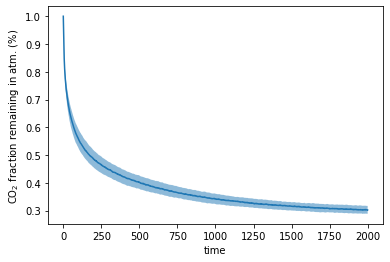

In [13]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"])
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.5)

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

#### Question 2: 

* What about other background CO2 ?
* How to interpret those different response ?

Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

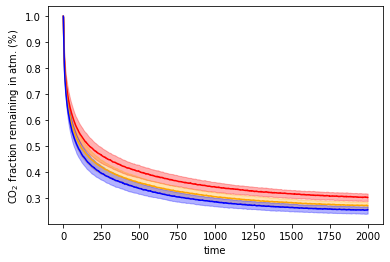

In [14]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_450_50"], color="orange")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_450_16"], df_co2["bg_450_84"], alpha=0.3, color="orange")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_425_50"], color="blue")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_425_16"], df_co2["bg_425_84"], alpha=0.3, color="blue")

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

#### Question 3: 

* Now, ptite question de cours : 
Quels sont les processus clefs qui retire du co2 de l'atm ?
Pression partielle a la surface de l'océan en premier lieu 
Et pour la biosphere c la photosynthèse
* Confirm your knwoledge with model data

Text(0.5, 1.0, 'b. land')

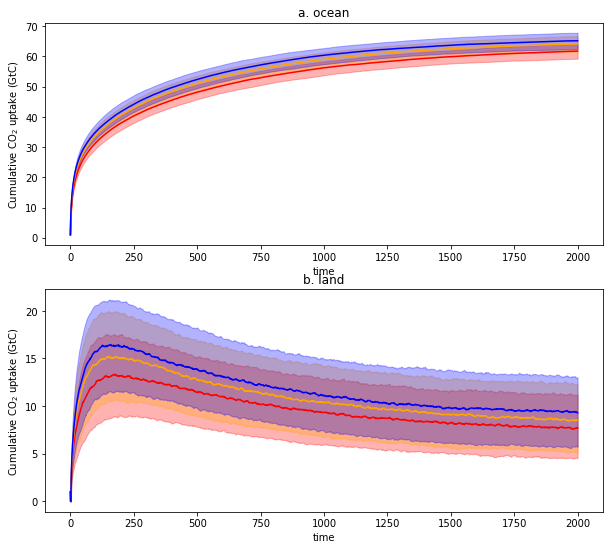

In [15]:
fig, axes = plt.subplots(2,1, figsize=(10, 9))

# Ocean
axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_500_50"], color="red")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_500_16"], df_ocean["bg_500_84"], alpha=0.3, color="red")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_450_50"], color="orange")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_450_16"], df_ocean["bg_450_84"], alpha=0.3, color="orange")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_425_50"], color="blue")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_425_16"], df_ocean["bg_425_84"], alpha=0.3, color="blue")

axes[0].set_xlabel("time")
axes[0].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[0].set_title("a. ocean")
# Land
axes[1].plot(df_land["yr_after_pulse"], df_land["bg_500_50"], color="red")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_500_16"], df_land["bg_500_84"], alpha=0.3, color="red")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_450_50"], color="orange")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_450_16"], df_land["bg_450_84"], alpha=0.3, color="orange")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_425_50"], color="blue")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_425_16"], df_land["bg_425_84"], alpha=0.3, color="blue")

axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[1].set_title("b. land")

<a id="section-1"></a>
## 2. Analytical representation

#### Question 4: 

* How much stays in the atmosphere after 10 years, 100 years, 1000 years ?
* How can we qualify the temporal evolution given by this model? Does this model behave linearly in function of time?
* A quoi vous fait penser la courbe de la question 1 precedente ? en terme de fonction analytique ?
* Tester un fit simple
* what do you think about your fit ?

__help:__ use function fmin

In [104]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0

time = df_co2["yr_after_pulse"]
def err_1exp(var):
    fit = var[0] + (1-var[0])*np.exp(-time/var[1])
    return sum(( fit[:10] - (df_co2["bg_500_50"][0:10]))**2)  # SSE (Sum of Squared Errors)
[a_0, tau_1] = fmin(err_1exp,[0, 100],disp=False)

a_1 = 1 - a_0

In [105]:
[a_0, a_1, tau_1]

[0.7165628120263976, 0.2834371879736024, 7.879690415626942]

Text(0, 0.5, 'Error')

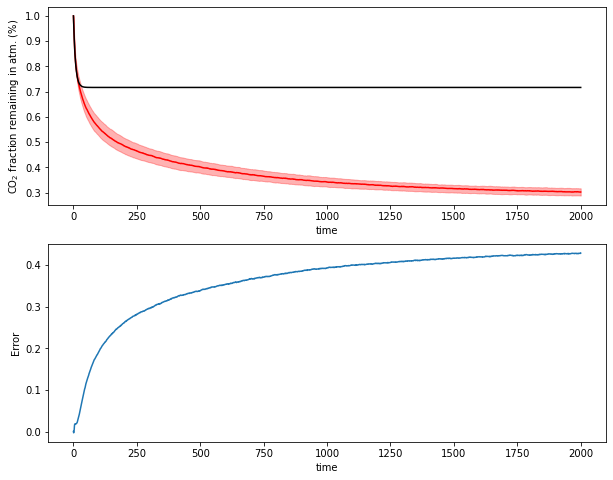

In [106]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1), color="k")


# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


#### Question 5: 

* Try improving this fit 

In [107]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0

time = df_co2["yr_after_pulse"]
def err_2exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + (1-var[1]-var[0])*np.exp(-time/var[3])
    return sum(( fit - (df_co2["bg_500_50"]))**2) # SSE (Sum of Squared Errors)
[a_0, a_1, tau_1, tau_2] = fmin(err_2exp,[0.5, 0.5, 10, 100],disp=False)

a_2 = 1 - a_1 - a_0


In [108]:
[a_0, a_1, a_2, tau_1, tau_2]

[0.3045711586021992,
 0.403230218253546,
 0.2921986231442548,
 23.261734311371452,
 458.24031802825505]

Text(0, 0.5, 'Error')

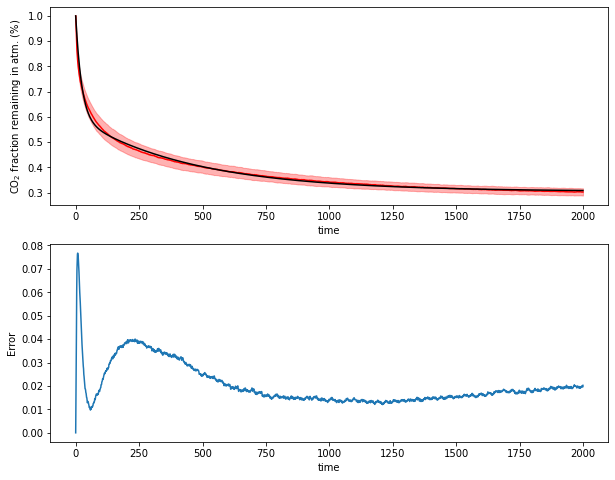

In [109]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2), color="k")

# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


#### Question 6: 

* mmmmh, still lacking some information, try to add another exp

In [110]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0
a_3 = 0
tau_3 = 0

time = df_co2["yr_after_pulse"]
def err_3exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + var[3]*np.exp(-time/var[4]) + (1-var[3]-var[1]-var[0])*np.exp(-time/var[5])
    return sum(( fit - (df_co2["bg_500_50"]))**2) # SSE (Sum of Squared Errors)
[a_0, a_1, tau_1, a_2, tau_2, tau_3] = fmin(err_3exp,[0.2, 0.2, 400, 0.2, 30, 3],disp=False)

a_3 = 1 - a_2 - a_1 - a_0


In [113]:
[a_0, a_1, a_2, a_3, tau_1, tau_2,  tau_3]

[0.2950196151560378,
 0.24700356259214584,
 0.24759548229442283,
 0.2103813399573935,
 597.9204731929267,
 65.73691968468935,
 6.921696890562096]

Text(0, 0.5, 'Error')

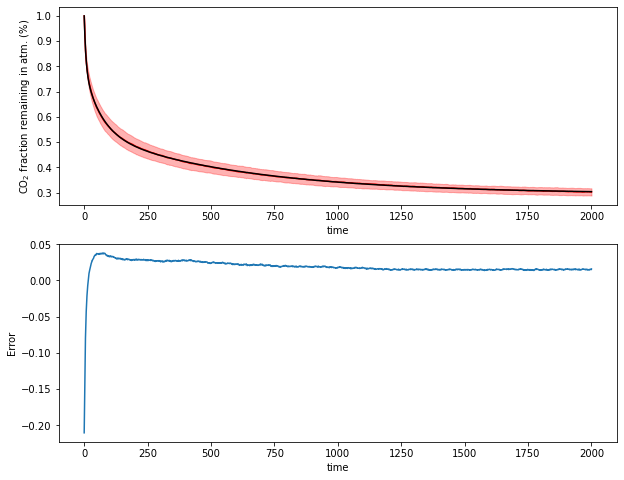

In [112]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
intermediaire = a_0 + a_1*np.exp(-time/tau_1) + a_2*np.exp(-time/tau_2) + a_3*np.exp(-time/tau_3)
axes[0].plot(year, intermediaire, color="k")

# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


In [118]:
a_0, a_1, a_2, a_3

(0.34371321424577106,
 -0.6695458195635815,
 -0.3676361128892592,
 1.6934687182070696)

In [119]:
tau_1, tau_2, tau_3

(111.24045339867, 77.12461977345001, 101.6863527521734)

In [137]:
def func(x, a_0, a_1, tau_1, a_2, tau_2, tau_3):
    return a_0 + a_1*np.exp(-x/tau_1) + a_2*np.exp(-x/tau_2) + (1-a_0-a_1-a_2)-np.exp(-x/tau_3)

popt, pcov = curve_fit(func, np.arange(1, 2002), df_co2['bg_500_50'])

/tmp/ipykernel_28426/2394422017.py:2: RuntimeWarning: overflow encountered in exp
  return a_0 + a_1*np.exp(-x/tau_1) + a_2*np.exp(-x/tau_2) + (1-a_0-a_1-a_2)-np.exp(-x/tau_3)
/tmp/ipykernel_28426/2394422017.py:4: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(func, np.arange(1, 2002), df_co2['bg_500_50'])


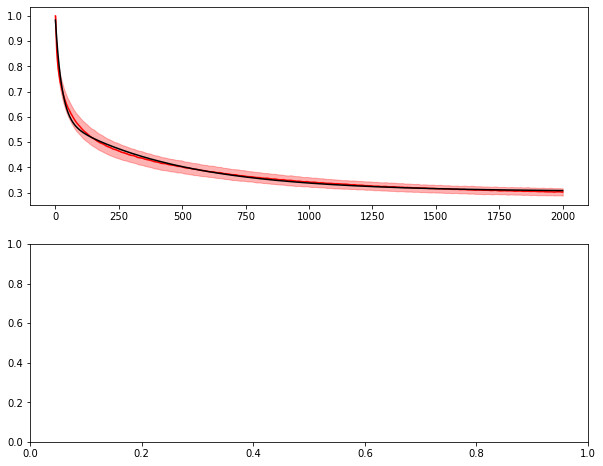

In [140]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].plot(np.arange(2001), func(np.arange(1, 2002), *popt), c='k')

#### Question 4:
* _According your knowledge, which Earth system components are simulated by the
various terms of the IRF equation ?_
* _What do they represent ? How do they evolve individually ?_

__Help__ : What are the units of $\tau_{C,}$ and $a_{C,}$ ?
